# OOVIRI – partea P1: adâncime în metri, ruta C și rutele de vot

Rulează cele 3 modele (Depth Anything V2, MiDaS, ZoeDepth) și ruta C (mediana per pixel), apoi ocluzia unui obiect virtual cu rutele de vot A, B, B-soft și C.

**Pe ce imagini:** lista `IMAGINI` din prima celulă de cod. Poate amesteca cele două surse:
- `../data/nyu_test/<id>.png`: imagini NYU. Lângă ele stă `<id>_depth.png` (adevărul, uint16 în mm): DA V2 și MiDaS se aliniază pe el și se calculează AbsRel, IoU și F1.
- `../data/photos/<nume>.jpg`: fotografiile proprii. Fără adevăr: DA V2 și MiDaS se aliniază pe ZoeDepth, iar pentru ocluzie hărțile se corectează pe punctele măsurate cu ruleta.

Ieșire în `outputs/`: `<id>_<metodă>.npy` (metri), `<id>_<metodă>.png`, `<id>_panel.png`; pentru ocluzie, `outputs/ocluzie/`.

Ordinea: prima celulă de cod, apoi secțiunea 1 (scrie hărțile), apoi oricare dintre celelalte. Secțiunea 5 nu depinde de `IMAGINI`. Înainte, o singură dată: `python scripts/download_nyu.py`.

In [52]:
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, "..")
from depth.run import process

# pe ce imagini rulăm: câteva din NYU (au adevăr) și câteva fotografii proprii
IMAGINI = [
    "../data/nyu_test/0003.png",
    "../data/nyu_test/0036.png",
    "../data/photos/foto_02_scaun_fata.jpg",
    "../data/photos/foto_04_monitor.jpg",
]

OUT = Path("../outputs")
METODE = ["depth_anything_v2", "midas", "zoedepth", "ruta_C"]
paths = [Path(p) for p in IMAGINI]
lipsa = [p.name for p in paths if not p.exists()]
assert not lipsa, f"nu există: {lipsa}"
print(len(paths), "imagini:", ", ".join(p.name for p in paths))

4 imagini: 0003.png, 0036.png, foto_02_scaun_fata.jpg, foto_04_monitor.jpg


## 1. Cele 3 modele + ruta C

Pe NYU: AbsRel (mai mic e mai bine) pe fiecare imagine, în crop-ul Eigen. Pe fotografii nu există adevăr, deci se afișează intervalul de adâncimi al fiecărei hărți.

In [53]:
for p in paths:
    scores = process(p, OUT)
    if scores:
        print(p.name, "  ".join(f"{m}: {s:.3f}" for m, s in scores.items()))
    else:
        harti = {m: np.load(OUT / f"{p.stem}_{m}.npy") for m in METODE}
        print(p.name, "  ".join(f"{m} {d.min():.2f}-{d.max():.2f} m" for m, d in harti.items()))

0003.png depth_anything_v2: 0.073  midas: 0.103  zoedepth: 0.267  ruta_C: 0.080
0036.png depth_anything_v2: 0.061  midas: 0.054  zoedepth: 0.060  ruta_C: 0.051
foto_02_scaun_fata.jpg depth_anything_v2 1.62-3.22 m  midas 1.62-3.05 m  zoedepth 1.02-3.44 m  ruta_C 1.62-3.16 m
foto_04_monitor.jpg depth_anything_v2 1.09-3.33 m  midas 1.12-3.03 m  zoedepth 0.91-3.03 m  ruta_C 1.09-3.03 m


## 2. Panourile: hărțile de adâncime ale modelelor și ale rutelor

- **Rândul 1:** imaginea și hărțile celor 3 modele (pe NYU și adevărul).
- **Rândul 2:** adâncimea rezultată din fiecare rută de vot.

Rutele A, B și B-soft votează pe măștile de ocluzie, dar fiecare are o adâncime echivalentă: un obiect virtual e ascuns de rută exact când e mai departe decât ea.
- **Ruta A** (vot majoritar, 2 din 3): mediana celor 3 adâncimi.
- **Ruta B** (vot ponderat): mediana ponderată, cu ponderile din `config/priors.json`. Cu 3 modele și ponderi apropiate iese tot mediana, adică B = A.
- **Ruta B-soft** (vot cu margine): adâncimea *D* la care votul trece de jumătate: Σ wᵢ·σ((D − dᵢ)/τᵢ) = ½·Σ wᵢ, cu τᵢ = AbsRelᵢ·dᵢ, eroarea tipică a modelului. Un model sigur trage *D* spre el.
- **Ruta C**: mediana celor 3 hărți, din secțiunea 1.

Pe NYU, sub fiecare hartă, AbsRel față de adevăr (mai mic e mai bine). Albastru = aproape, roșu = departe; aceeași scală de culori în tot panoul.

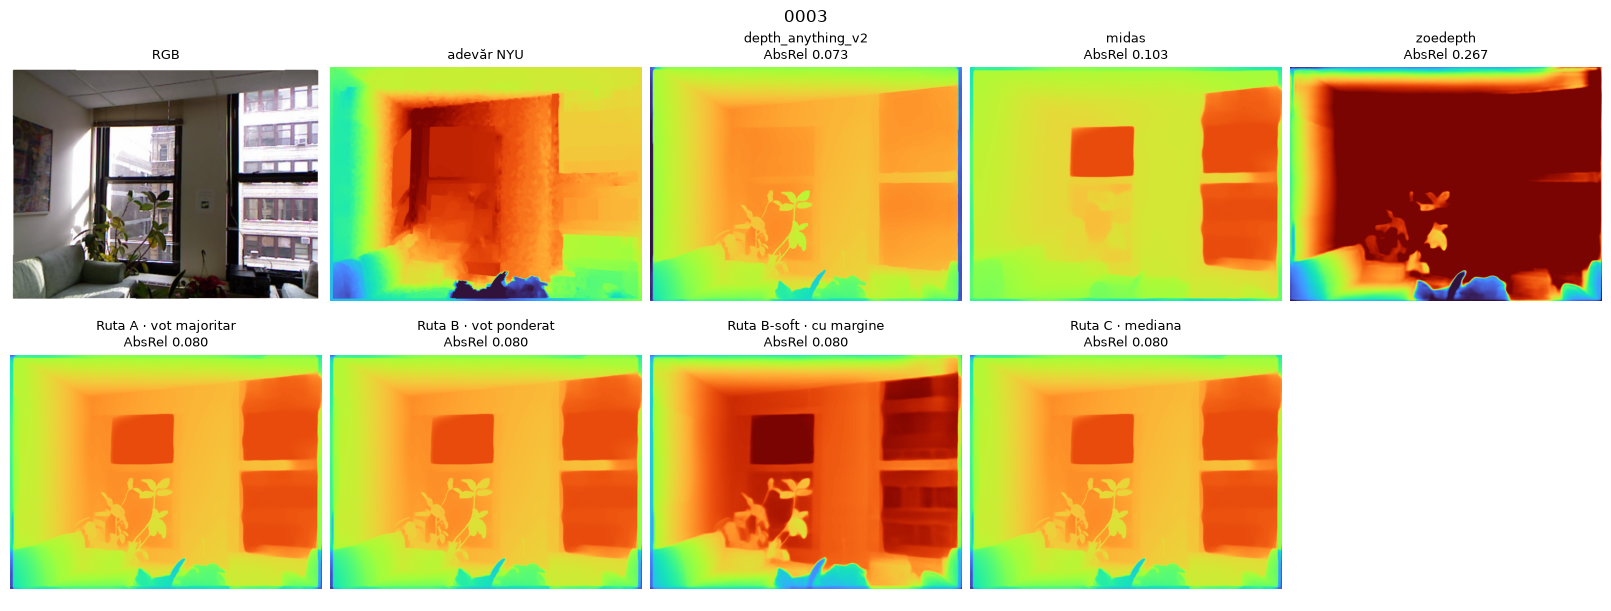

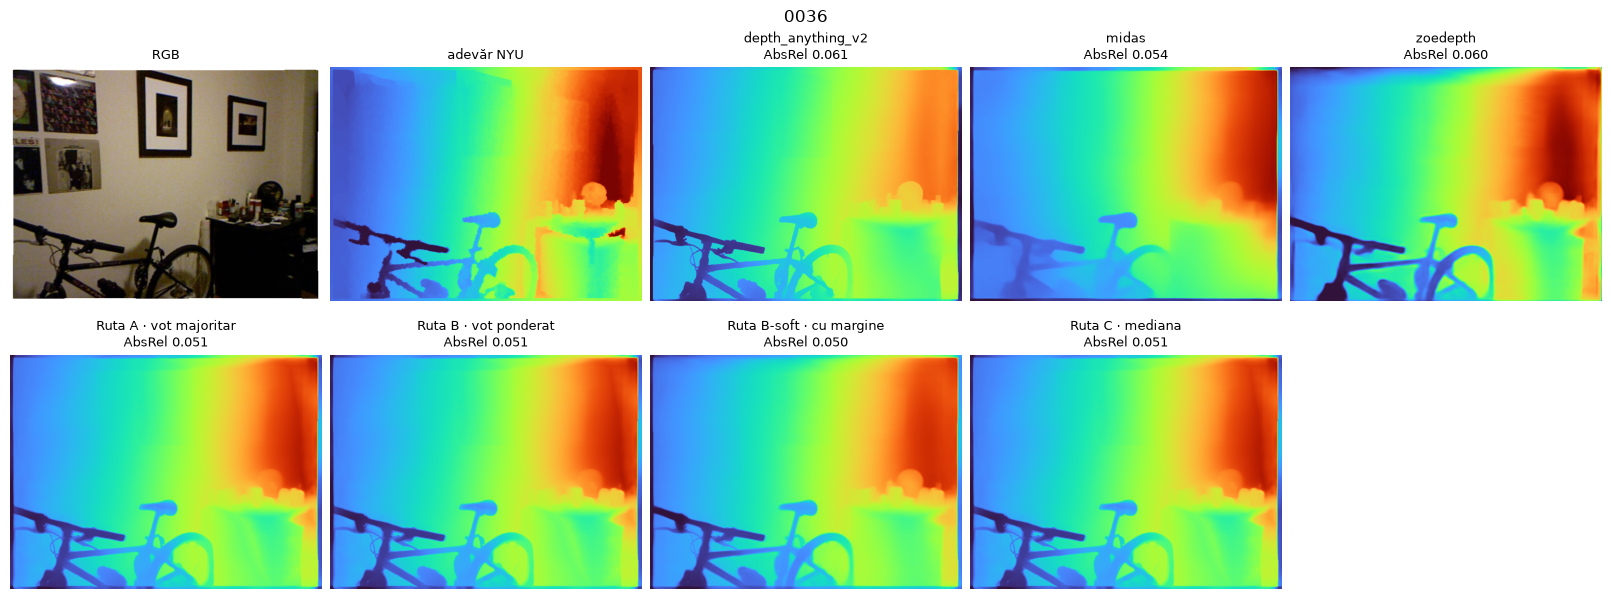

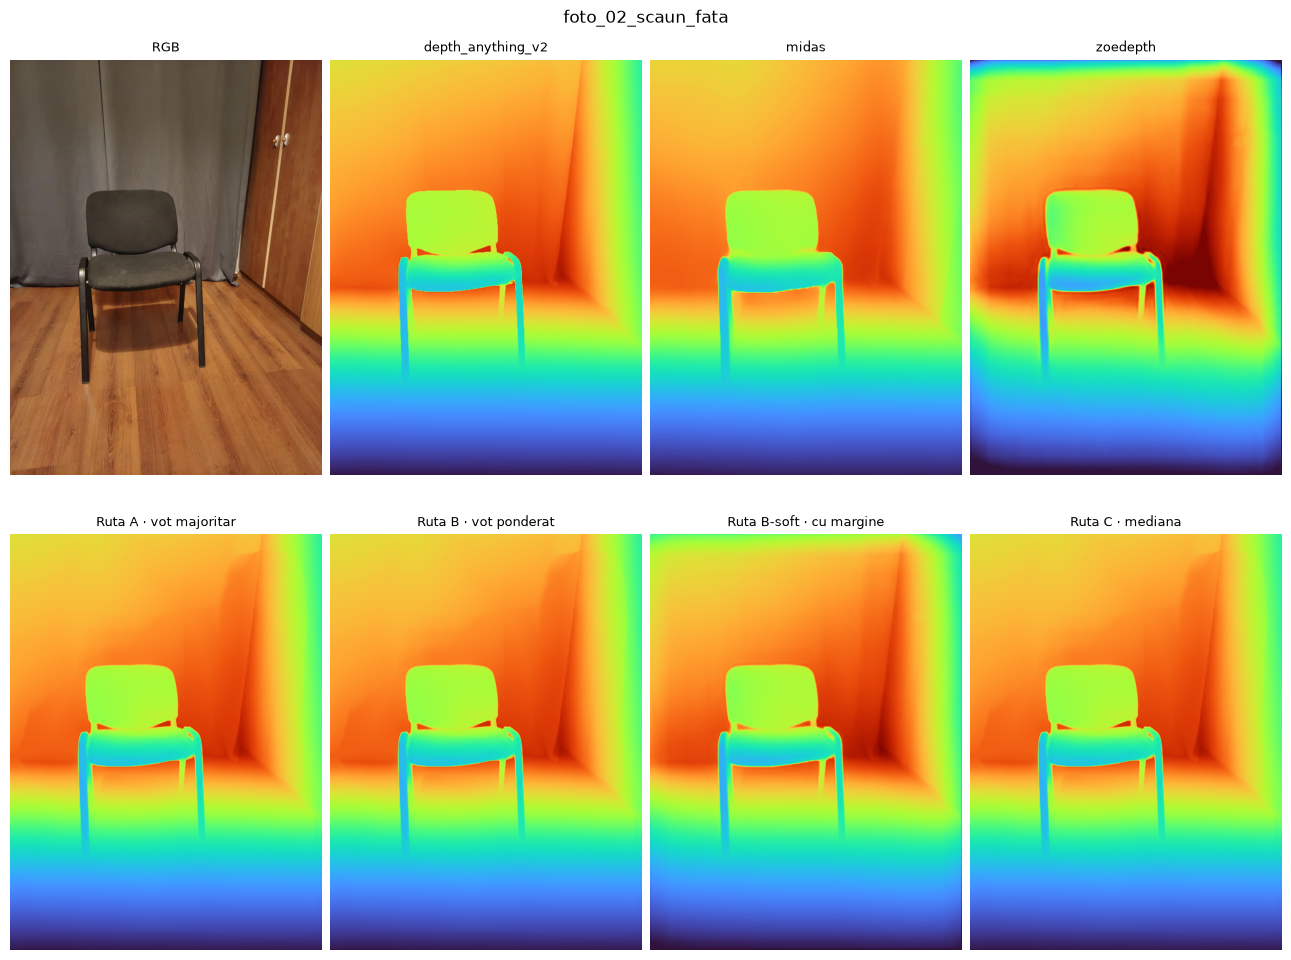

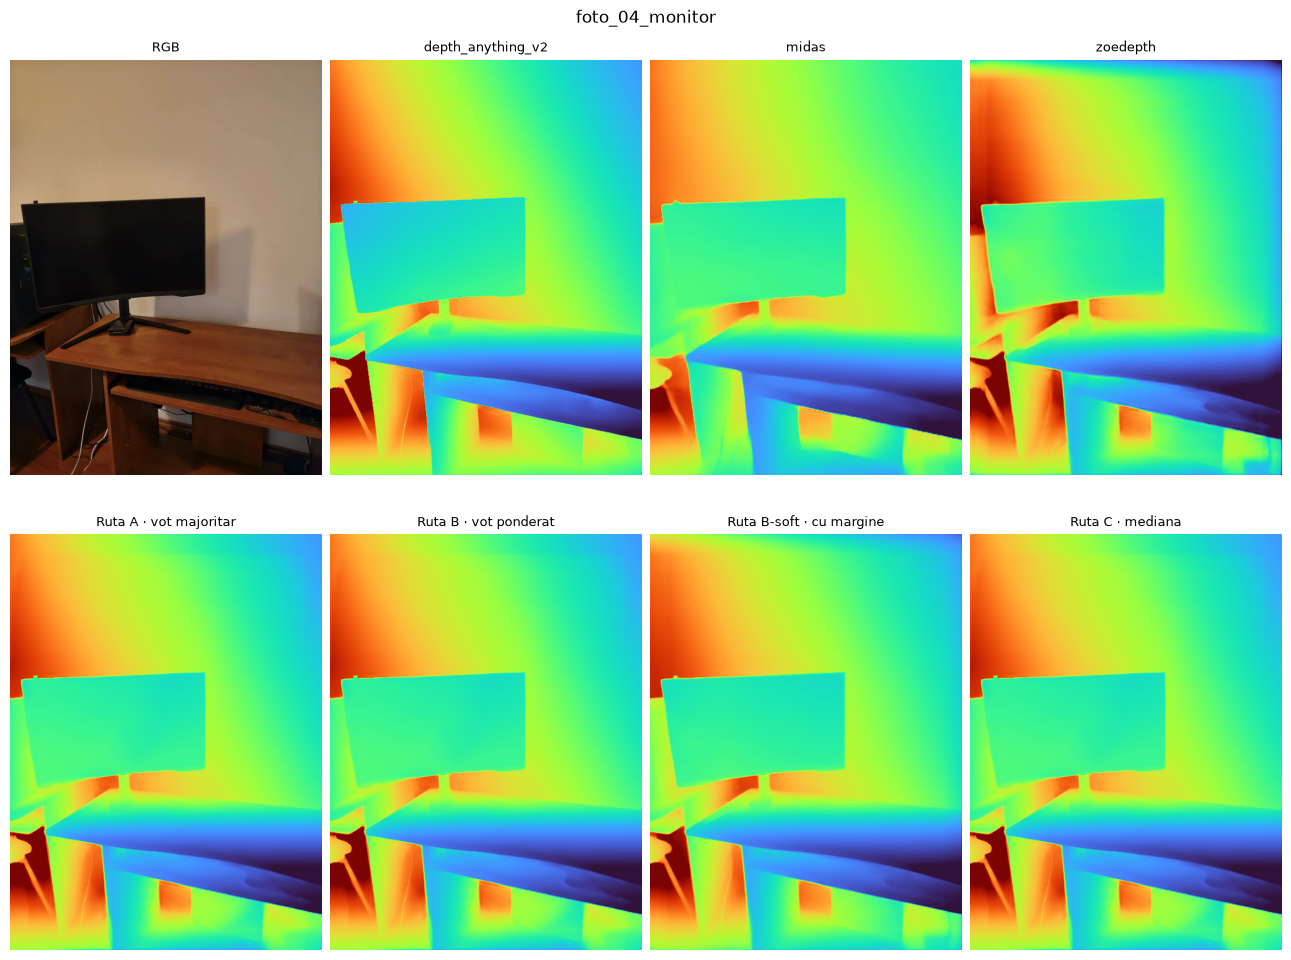

In [54]:
import matplotlib.pyplot as plt
from depth.run import load_gt
from evaluation.metrics import depth_metrics
from ooviri.depthio import load_rgb
from ooviri.pipeline import load_priors

PRIORS = load_priors("../config/priors.json")   # ponderea și AbsRel-ul fiecărui model
MODELE = ["depth_anything_v2", "midas", "zoedepth"]
W = np.array([PRIORS[m].weight for m in MODELE])
ABS_REL = np.array([PRIORS[m].abs_rel for m in MODELE])


def ruta_a(d):
    """Vot majoritar: obiectul e ascuns când e în spatele a cel puțin 2 din 3 hărți, adică în spatele medianei."""
    return np.median(d, axis=0)


def ruta_b(d, w):
    """Vot ponderat: mediana ponderată, prima adâncime (în ordine crescătoare) care strânge peste jumătate din greutate."""
    ordine = np.argsort(d, axis=0)
    sortate = np.take_along_axis(d, ordine, axis=0)
    cumulat = np.cumsum(w[ordine], axis=0)
    k = np.argmax(cumulat > 0.5 * w.sum(), axis=0)
    return np.take_along_axis(sortate, k[None], axis=0)[0]


def ruta_b_soft(d, w, abs_rel, pasi=40):
    """Vot cu margine: D cu sum(w·σ((D − d)/τ)) = ½·sum(w), τ = AbsRel·d; găsit prin înjumătățirea intervalului."""
    tau = np.maximum(abs_rel[:, None, None] * d, 1e-3)
    jos, sus = d.min(axis=0), d.max(axis=0)   # rădăcina e mereu între cea mai mică și cea mai mare adâncime
    for _ in range(pasi):
        mijloc = (jos + sus) / 2
        scor = (w[:, None, None] / (1 + np.exp(-np.clip((mijloc - d) / tau, -60, 60)))).sum(axis=0)
        ascuns = scor > 0.5 * w.sum()   # la adâncimea asta obiectul ar fi deja ascuns: rădăcina e mai aproape
        sus, jos = np.where(ascuns, mijloc, sus), np.where(ascuns, jos, mijloc)
    return (jos + sus) / 2


for p in paths:
    rgb = load_rgb(p)
    gt = load_gt(p)   # adevărul NYU; None pe fotografii
    harti = {m: np.load(OUT / f"{p.stem}_{m}.npy") for m in MODELE}   # hărțile din secțiunea 1
    d = np.stack(list(harti.values())).astype(np.float64)
    rute = {
        "Ruta A · vot majoritar": ruta_a(d),
        "Ruta B · vot ponderat": ruta_b(d, W),
        "Ruta B-soft · cu margine": ruta_b_soft(d, W, ABS_REL),
        "Ruta C · mediana": np.load(OUT / f"{p.stem}_ruta_C.npy"),
    }
    ref = gt if gt is not None else harti["zoedepth"]
    vmin, vmax = np.percentile(ref[ref > 0], [1, 99])
    rand_1 = [("RGB", rgb)] + ([("adevăr NYU", gt)] if gt is not None else []) + list(harti.items())
    coloane = max(len(rand_1), len(rute))

    fig, axes = plt.subplots(2, coloane, figsize=(3.2 * coloane, 2 * 3.2 * rgb.shape[0] / rgb.shape[1] + 1.2),
                             layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    for rand_ax, rand in zip(axes, [rand_1, list(rute.items())]):
        for ax, (titlu, im) in zip(rand_ax, rand):
            ax.imshow(im, cmap="turbo", vmin=vmin, vmax=vmax)
            if gt is not None and im is not rgb and im is not gt:
                titlu += f"\nAbsRel {depth_metrics(np.asarray(im, np.float32), gt)['AbsRel']:.3f}"
            ax.set_title(titlu, fontsize=9)
    fig.suptitle(p.stem)
    plt.show()

## 3. Ocluzia: modelele și rutele de vot, cu un obiect virtual

Un obiect virtual pus în scenă; fiecare model decide, pixel cu pixel, ce parte din obiect e ascunsă, apoi rutele combină deciziile. Imaginile sunt mărite pe obiect.

- **Rândul 1:** fără ocluzie și cele 3 modele, fiecare cu masca lui; pe NYU și referința, adică masca obținută din adâncimea reală.
- **Rândul 2:** rutele A (vot majoritar), B (vot ponderat), B-soft (vot cu margine) și C (mediana adâncimii).

Unde e pus obiectul:
- **pe fotografii:** cazurile din `data/photos/plasari.json`; hărțile se corectează întâi pe punctele măsurate cu ruleta, ca în `python -m ooviri batch`;
- **pe NYU:** `N_ALEATOARE` plasări aleatoare, reproductibile, la o adâncime între cea mai apropiată și cea mai îndepărtată suprafață din jur; se păstrează doar cele pe care adâncimea reală le ascunde parțial (`ASCUNS_NYU`, implicit 20–80% din obiect), ca să se vadă unde greșesc modelele.

„ascuns” = cât din obiect e acoperit; pe NYU și IoU față de referință (mai mare e mai bine). Măștile, imaginile AR, panourile `ooviri` și un raport JSON se scriu în `outputs/ocluzie/`.

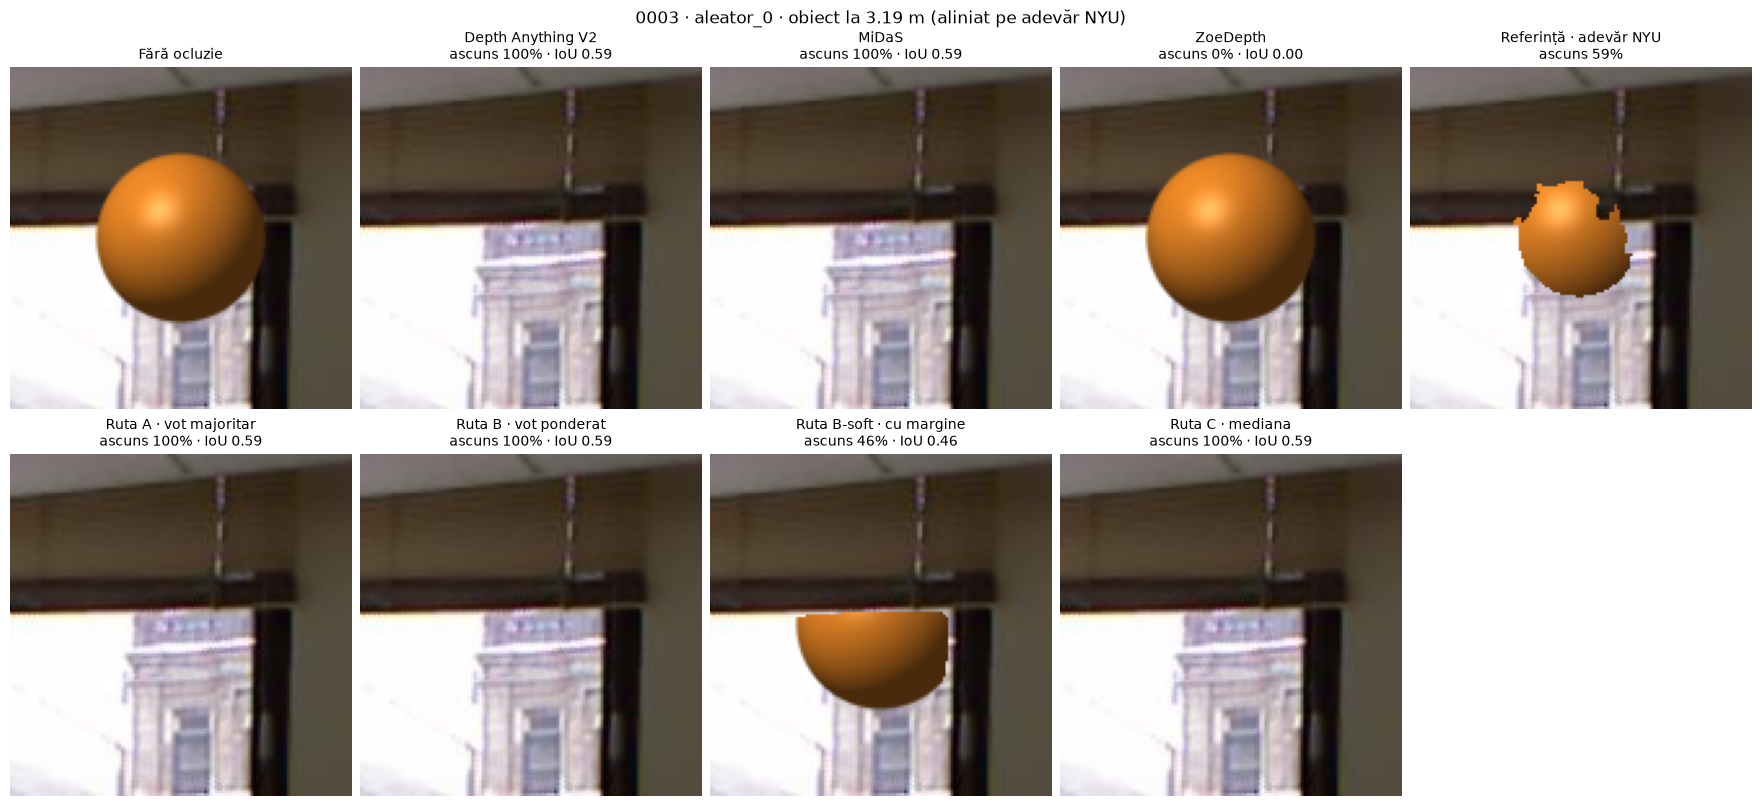

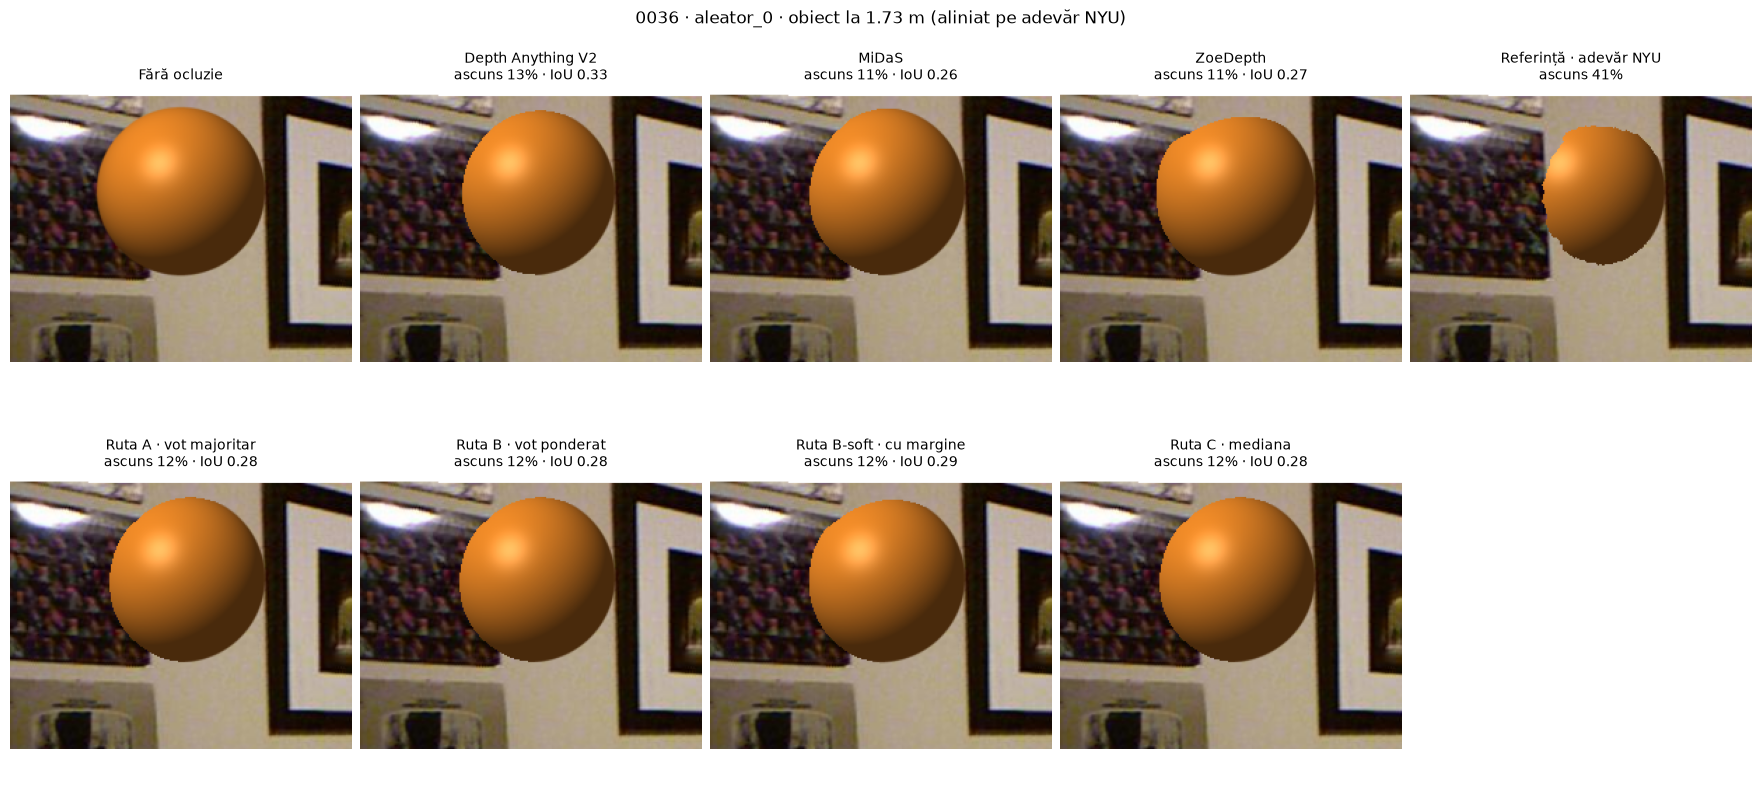

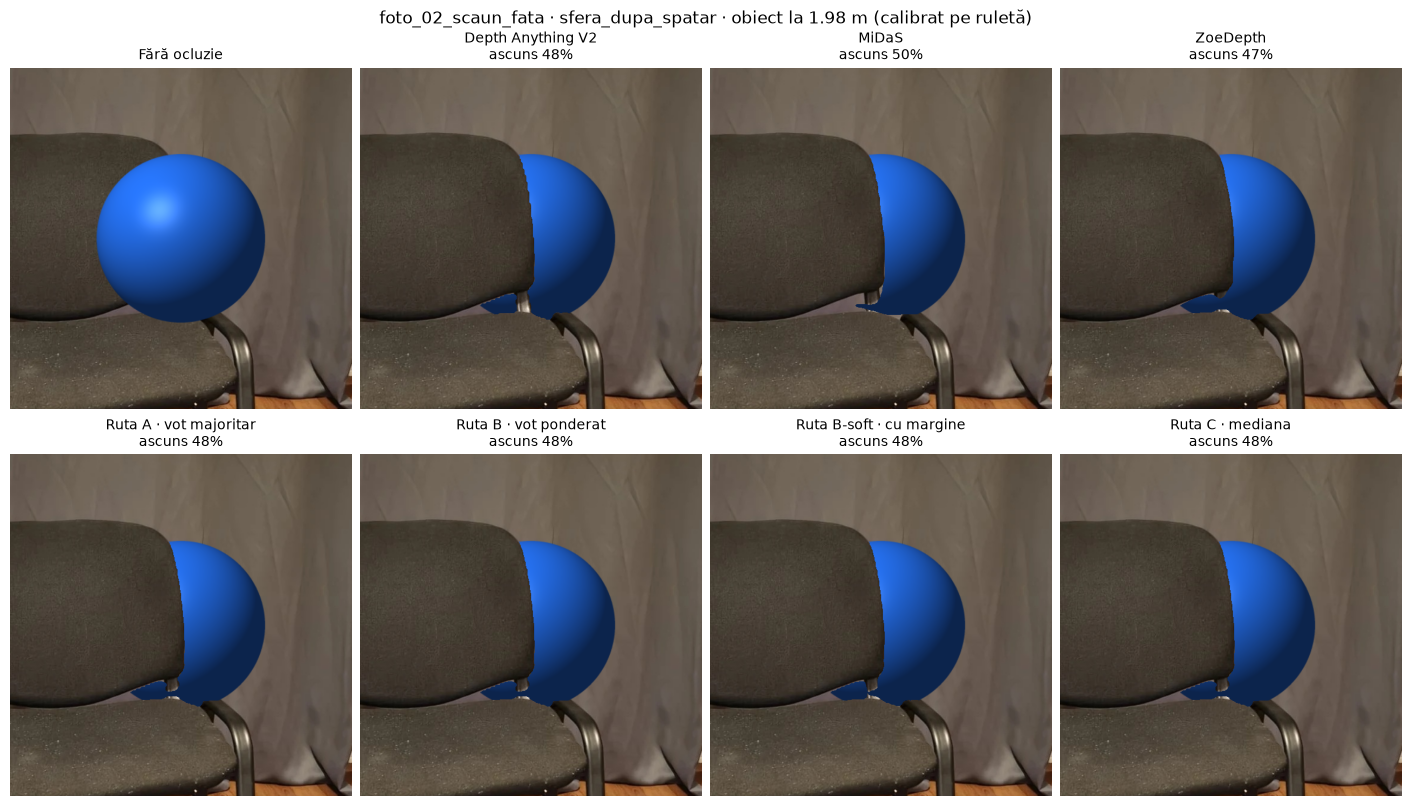

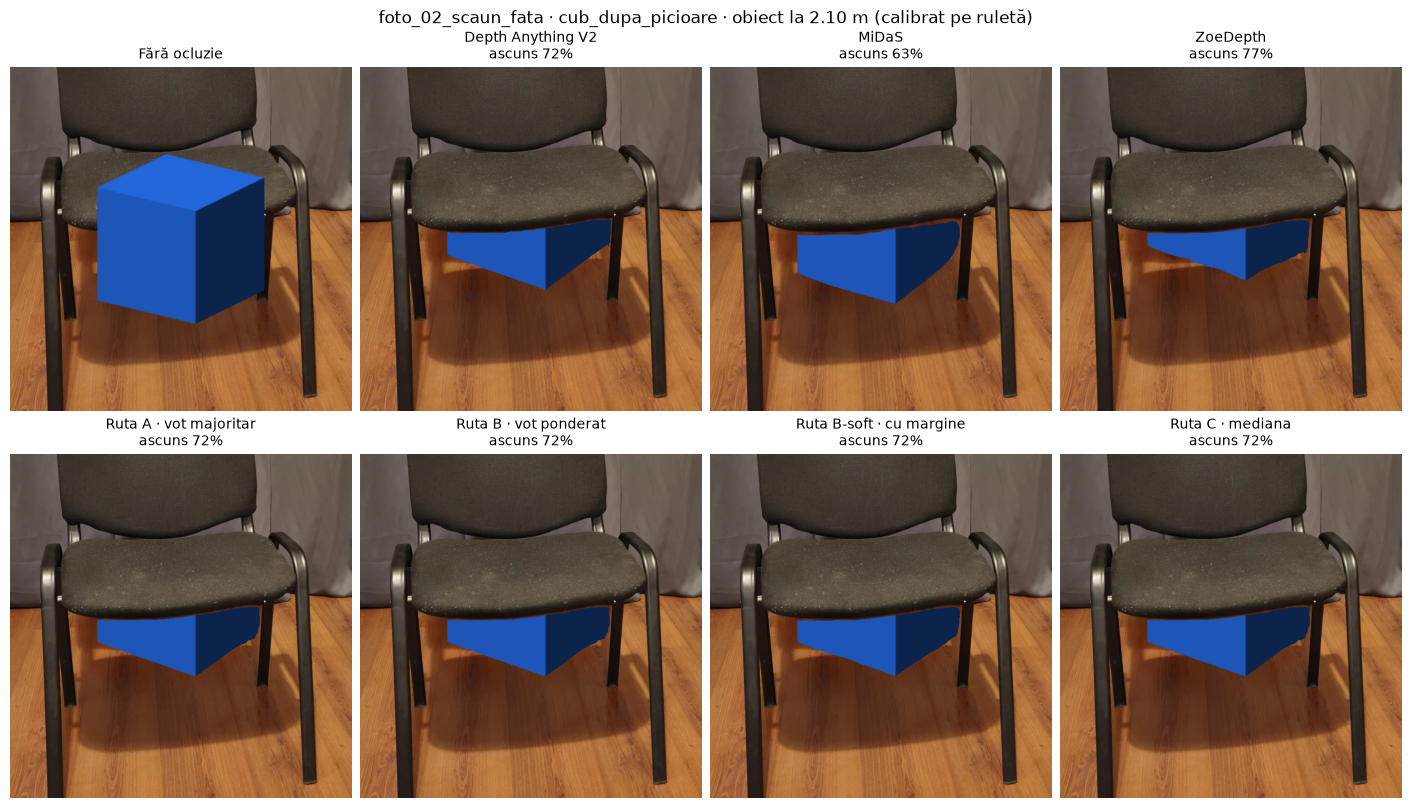

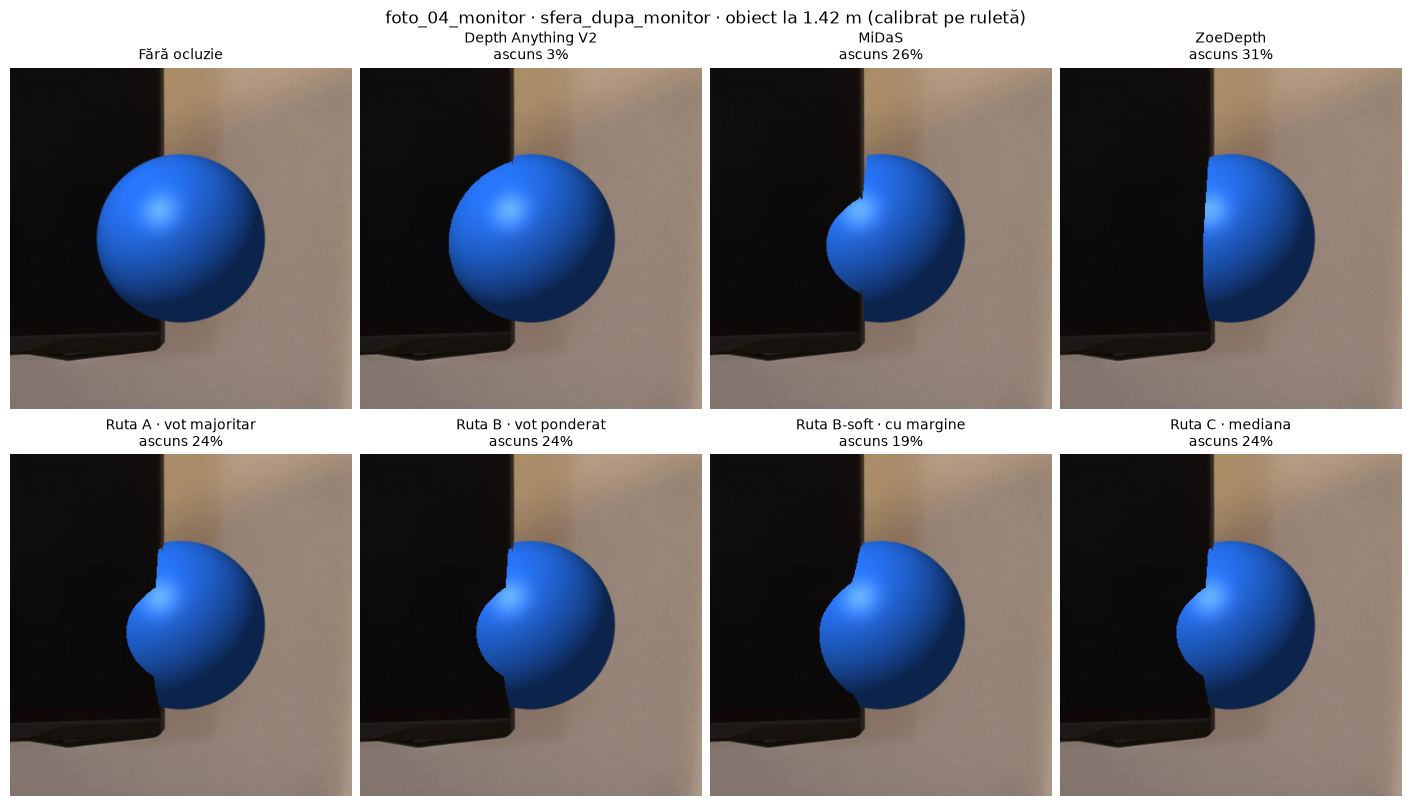

In [55]:
import json

from ooviri.camera import NYU, Camera
from ooviri.compose import crop
from ooviri.measure import calibrate_depth, load_control_points, sample_depth
from ooviri.occlusion import occlusion_mask
from ooviri.pipeline import run, save_outputs
from ooviri.placement import Placement, place, random_placements
from ooviri.sprite import PRIMITIVES

PLASARI = json.loads(Path("../data/photos/plasari.json").read_text(encoding="utf-8"))
MASURATORI = Path("../data/photos/masuratori.json")
MASURATE = json.loads(MASURATORI.read_text(encoding="utf-8"))["poze"]
FOCAL35 = 24       # telefonul pozelor din data/photos (Motorola Edge 60, obiectivul principal)
N_ALEATOARE = 1    # câte plasări aleatoare pe imaginile fără plasări fixe (NYU)
ASCUNS_NYU = (0.2, 0.8)   # pe NYU păstrăm doar plasările pe care adevărul le ascunde parțial
RAND_1 = [("fara_ocluzie", "Fără ocluzie"), ("depth_anything_v2", "Depth Anything V2"),
          ("midas", "MiDaS"), ("zoedepth", "ZoeDepth")]
RAND_2 = [("ruta_A", "Ruta A · vot majoritar"), ("ruta_B", "Ruta B · vot ponderat"),
          ("ruta_B_soft", "Ruta B-soft · cu margine"), ("ruta_C", "Ruta C · mediana")]


def cazuri(p, ref, camera):
    """Plasările fixe din plasari.json; altfel (NYU) plasări aleatoare, reproductibile."""
    if p.stem in PLASARI:
        h, w = ref.shape
        for caz in PLASARI[p.stem]:
            zi = caz["z_intre"]   # adâncimea obiectului, între două repere din poză
            fata = sample_depth(ref, tuple(zi["fata"]), (w, h))
            spate = sample_depth(ref, tuple(zi["spate"]), (w, h))
            z = fata + zi.get("t", 0.5) * (spate - fata)
            sprite = PRIMITIVES[caz["sprite"]](color=tuple(caz["culoare"]))
            yield caz["nume"], sprite, Placement(x=caz["x"], y=caz["y"], z=z, scale=caz.get("scale", 1.0))
    else:
        sprite = PRIMITIVES["sphere"]()
        seed = int(p.stem) if p.stem.isdigit() else 0
        candidati = random_placements(ref, sprite, camera, 50, seed=seed)

        def ascuns(plasare):   # cât din obiect ascunde adâncimea de referință
            pus = place(sprite, plasare, camera)
            return occlusion_mask(ref, pus).sum() / max(pus.footprint.sum(), 1)

        bune = [c for c in candidati if ASCUNS_NYU[0] <= ascuns(c) <= ASCUNS_NYU[1]] or candidati
        for i, plasare in enumerate(bune[:N_ALEATOARE]):
            yield f"aleator_{i}", sprite, plasare


def ocluzia(p):
    """Toate cazurile unei imagini: [(nume, rezultat, cum s-a stabilit scara)]."""
    rgb = load_rgb(p)
    h, w = rgb.shape[:2]
    gt = load_gt(p)
    camera = NYU.resized(w, h) if gt is not None else Camera.from_focal35(w, h, FOCAL35)
    harti = {m: np.load(OUT / f"{p.stem}_{m}.npy") for m in MODELE}
    points = load_control_points(MASURATORI, p.stem)[0] if p.stem in MASURATE else []
    if points:   # fiecare model corectat pe punctele măsurate cu ruleta, ca în ooviri batch
        harti = {m: calibrate_depth(d, points, (w, h))[0] for m, d in harti.items()}
    # ruta C = mediana hărților; primește mască proprie, dar nu votează
    ruta_c = {"ruta_C": np.median(np.stack(list(harti.values())), axis=0).astype(np.float32)}
    ref = gt if gt is not None else ruta_c["ruta_C"]
    scara = "aliniat pe adevăr NYU" if gt is not None else ("calibrat pe ruletă" if points else "necalibrat")
    rezultate = []
    for nume, sprite, plasare in cazuri(p, ref, camera):
        res = run(rgb, harti, sprite, plasare, camera=camera, priors=PRIORS, gt_depth=gt, extra_depths=ruta_c)
        save_outputs(res, rgb, OUT / "ocluzie", f"{p.stem}__{nume}", depths=harti, gt_depth=gt, extra_depths=ruta_c)
        rezultate.append((nume, res, scara))
    return rezultate


def eticheta(titlu, cheie, res):
    """Titlul unei imagini AR: cât din obiect e ascuns și, pe NYU, IoU față de referință."""
    m = {**res.model_masks, **{f"ruta_{r}": v for r, v in res.route_masks.items()}, **res.extra_masks}
    if res.gt_mask is not None:
        m["referinta"] = res.gt_mask
    if cheie in m:
        titlu += f"\nascuns {m[cheie].sum() / res.placed.footprint.sum():.0%}"
    if cheie in res.scores:
        titlu += f" · IoU {res.scores[cheie]['iou']:.2f}"
    return titlu


for p in paths:
    for nume, res, scara in ocluzia(p):
        rand_1 = RAND_1 + ([("referinta", "Referință · adevăr NYU")] if res.gt_mask is not None else [])
        x0, y0, x1, y1 = res.placed.bbox
        margine = max(x1 - x0, y1 - y0) // 2   # zoom pe obiect, cu puțin context în jur

        fig, axes = plt.subplots(2, len(rand_1), figsize=(3.5 * len(rand_1), 8), layout="constrained")
        for rand_ax, rand in zip(axes, [rand_1, RAND_2]):
            for ax in rand_ax:
                ax.axis("off")
            for ax, (cheie, titlu) in zip(rand_ax, rand):
                ax.imshow(crop(res.composites[cheie], res.placed.bbox, margine))
                ax.set_title(eticheta(titlu, cheie, res), fontsize=10)
        fig.suptitle(f"{p.stem} · {nume} · obiect la {res.placement.z:.2f} m ({scara})")
        plt.show()

## 4. O hartă în metri, comparată cu adevărul

`METODA`: `depth_anything_v2`, `midas`, `zoedepth` sau `ruta_C`. Pe fotografii nu există adevăr, deci se vede doar harta.

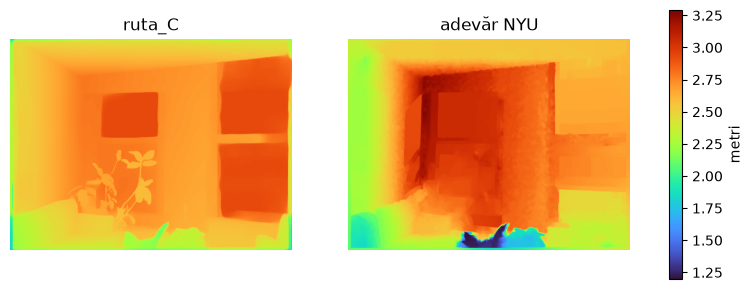

pixelul (240, 320): ruta_C = 2.76 m, adevăr = 3.03 m


In [56]:
import matplotlib.pyplot as plt
from depth.run import load_gt

METODA = "ruta_C"
P = paths[0]   # prima imagine aleasă

d = np.load(OUT / f"{P.stem}_{METODA}.npy")
gt = load_gt(P)
harti = [(METODA, d)] + ([("adevăr NYU", gt)] if gt is not None else [])
vmin, vmax = (gt.min(), gt.max()) if gt is not None else np.percentile(d, [1, 99])

fig, axes = plt.subplots(1, len(harti), figsize=(5 * len(harti), 3.5), squeeze=False)
for ax, (titlu, harta) in zip(axes[0], harti):
    im = ax.imshow(harta, cmap="turbo", vmin=vmin, vmax=vmax)
    ax.set_title(titlu)
    ax.axis("off")
fig.colorbar(im, ax=axes, label="metri")
plt.show()

r, c = d.shape[0] // 2, d.shape[1] // 2   # pixelul din centru
print(f"pixelul ({r}, {c}): {METODA} = {d[r, c]:.2f} m" + (f", adevăr = {gt[r, c]:.2f} m" if gt is not None else ""))

## 5. Evaluarea pe setul de test NYU

AbsRel, RMSE, δ1 și timpul pe imagine, pentru fiecare model și ruta C, cu aliniere pe adevăr (`gt`) și pe ZoeDepth. Rulează mereu pe NYU, indiferent de `IMAGINI`. `N = 654` rulează tot setul (~2 minute pe GPU); aici un subset, pentru viteză.

In [57]:
import csv
import subprocess

N = 50
subprocess.run([sys.executable, "-m", "evaluation.run", "--n", str(N), "--out", "outputs/eval_depth.csv"],
               cwd="..", capture_output=True, check=True)

with open(OUT / "eval_depth.csv", encoding="utf-8") as f:
    rows = list(csv.reader(f))
for row in rows:
    print("".join(f"{x:<20}" if i < 2 else f"{x:>9}" for i, x in enumerate(row)))

metoda              aliniere               AbsRel     RMSE   delta1    s_img
depth_anything_v2   gt                     0.0992   0.4948   0.9018   0.0187
midas               gt                     0.1180   0.5620   0.8673   0.0330
zoedepth            gt                     0.1038   0.4801   0.9036   0.0663
ruta_C              gt                     0.0903   0.4631   0.9202   0.1180
depth_anything_v2   zoedepth               0.1276   0.5934   0.8480   0.0187
midas               zoedepth               0.1372   0.6101   0.8203   0.0330
zoedepth            zoedepth               0.1038   0.4801   0.9036   0.0663
ruta_C              zoedepth               0.1142   0.5348   0.8793   0.1180


## 6. Distanțele față de ruletă (fotografiile proprii)

Doar pentru pozele din `data/photos/masuratori.json`, deci pentru pozele din `IMAGINI` care sunt din `data/photos`. Pentru fiecare punct măsurat: adâncimea așteptată, cea din fiecare hartă (înainte de corecție) și eroarea în procente. Ultima linie e corecția de scară și decalaj pe care o aplică secțiunea 3. `~` = distanță aproximativă (înălțimea telefonului nu e cunoscută).

In [58]:
import json

from ooviri.measure import calibrate_depth, load_control_points, sample_depth

MASURATORI = Path("../data/photos/masuratori.json")
MASURATE = json.loads(MASURATORI.read_text(encoding="utf-8"))["poze"]

cu_puncte = [p for p in paths if p.stem in MASURATE]
if not cu_puncte:
    print("nicio imagine cu puncte măsurate: adaugă în IMAGINI o poză din ../data/photos")
for p in cu_puncte:
    points, camera, _ = load_control_points(MASURATORI, p.stem)
    if not points:
        print(f"{p.stem}: fără puncte măsurate\n")
        continue
    size = (camera.width, camera.height)
    harti = {m: np.load(OUT / f"{p.stem}_{m}.npy") for m in METODE}
    print(p.stem)
    for pt in points:
        valori = {m: sample_depth(d, pt.pixel, size) for m, d in harti.items()}
        print(f"  {pt.name:<44} ruletă {'~' if pt.approximate else ' '}{pt.depth:.2f} m   "
              + "  ".join(f"{m} {v:.2f} ({(v - pt.depth) / pt.depth:+.0%})" for m, v in valori.items()))
    corectii = {m: calibrate_depth(d, points, size)[1] for m, d in harti.items()}
    print("  corecția: adevărat = a × hartă + b   "
          + "  ".join(f"{m}: a={c.scale:.2f} b={c.offset:+.2f} m" for m, c in corectii.items()) + "\n")

foto_02_scaun_fata
  piciorul din fata dreapta, la podea          ruletă  1.37 m   depth_anything_v2 2.18 (+59%)  midas 2.16 (+58%)  zoedepth 2.25 (+64%)  ruta_C 2.18 (+59%)
  piciorul din spate dreapta, la podea         ruletă  1.78 m   depth_anything_v2 2.56 (+44%)  midas 2.49 (+40%)  zoedepth 2.63 (+48%)  ruta_C 2.56 (+44%)
  perdeaua la podea, in dreapta scaunului      ruletă  2.41 m   depth_anything_v2 3.05 (+26%)  midas 2.98 (+24%)  zoedepth 3.25 (+35%)  ruta_C 3.05 (+26%)
  corecția: adevărat = a × hartă + b   depth_anything_v2: a=1.21 b=-1.28 m  midas: a=1.28 b=-1.39 m  zoedepth: a=1.04 b=-0.96 m  ruta_C: a=1.21 b=-1.28 m

foto_04_monitor
  ecranul monitorului, centru                  ruletă ~1.28 m   depth_anything_v2 1.72 (+34%)  midas 1.80 (+40%)  zoedepth 1.80 (+40%)  ruta_C 1.80 (+40%)
  peretele din dreapta monitorului             ruletă ~1.53 m   depth_anything_v2 1.89 (+23%)  midas 1.97 (+28%)  zoedepth 1.86 (+22%)  ruta_C 1.89 (+23%)
  corecția: adevărat = a × hartă + 